# Figure 7f. INO80E indirect associations with DLPFC ABCA1

Forest plot of the indirect effect of the chr16 AD lead variant (chr16:29951481:G:A) on DLPFC *ABCA1* expression (a *trans*-eGene) through *INO80E* expression in five contexts. Estimates are single-mediator indirect effects with 95% donor-bootstrap percentile confidence intervals (1,000 resamples). Orange marks a 95% CI that excludes 0; this is nominal (the table also shows bootstrap p and the BH q across all 15 tested mediators, all > 0.17).

Input: `data/Figure_7f_INO80E_mediation.rds`

In [1]:
library(ggplot2)
d <- readRDS("data/Figure_7f_INO80E_mediation.rds")
d

mediator,mediator_context,outcome,snp,indirect_effect,ci_lower,ci_upper,ci_method,bootstrap_p,BH_q_global,n_complete,n_bootstrap,ci_excludes_0
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<int>,<int>,<lgl>
INO80E (Exc),Exc,ABCA1 DLPFC,chr16:29951481:G:A,0.069335830,0.0053504242,0.14194301,95% donor-bootstrap percentile CI,0.03796204,0.2022977,386,1000,TRUE
INO80E (Oli),Oli,ABCA1 DLPFC,chr16:29951481:G:A,0.043271658,0.0119384549,0.08020485,95% donor-bootstrap percentile CI,0.01198801,0.1798202,386,1000,TRUE
INO80E (DLPFC),DLPFC,ABCA1 DLPFC,chr16:29951481:G:A,0.034769991,-0.0001611819,0.07403289,95% donor-bootstrap percentile CI,0.05394605,0.2022977,784,1000,FALSE
INO80E (Ast),Ast,ABCA1 DLPFC,chr16:29951481:G:A,0.010482765,-0.0213163357,0.04440105,95% donor-bootstrap percentile CI,0.52747253,0.8791209,386,1000,FALSE
INO80E (Inh),Inh,ABCA1 DLPFC,chr16:29951481:G:A,-0.003845335,-0.0316015507,0.02577241,95% donor-bootstrap percentile CI,0.79520480,0.9390609,386,1000,FALSE


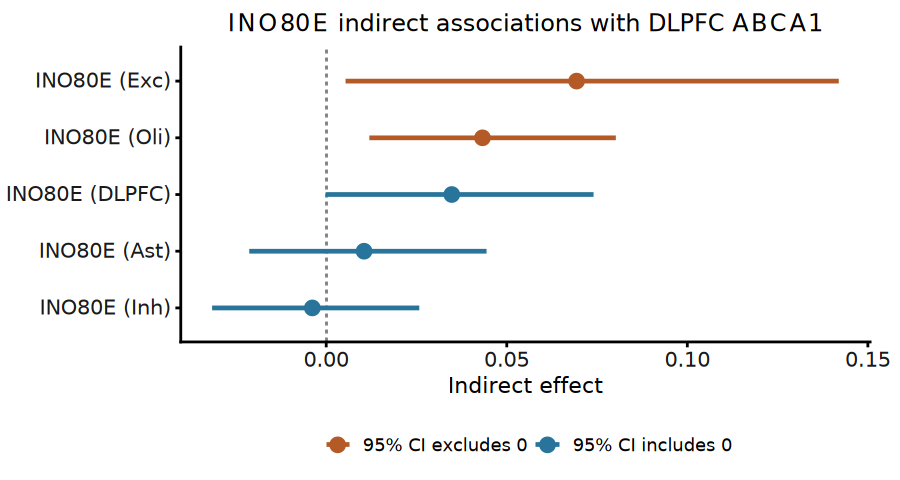

In [2]:
TITLE <- expression(italic(INO80E) * " indirect associations with DLPFC " * italic(ABCA1))
d <- d[order(-abs(d$indirect_effect), d$mediator), ]
d$mediator <- factor(d$mediator, levels = rev(d$mediator))
gene <- sub(" \\(.*$", "", levels(d$mediator))
ctx  <- sub("^.* \\((.*)\\)$", "\\1", levels(d$mediator))
labs_expr <- parse(text = paste0('italic("', gene, '")~"(', ctx, ')"'))
d$status <- ifelse(d$ci_excludes_0, "95% CI excludes 0", "95% CI includes 0")

p <- ggplot(d, aes(x = indirect_effect, y = mediator, colour = status)) +
  geom_vline(xintercept = 0, linetype = 2, colour = "grey50") +
  geom_errorbar(aes(xmin = ci_lower, xmax = ci_upper), orientation = "y", width = 0, linewidth = 1) +
  geom_point(size = 3.5) +
  scale_colour_manual(values = c("95% CI excludes 0" = "#B35A27", "95% CI includes 0" = "#28749A")) +
  scale_y_discrete(labels = labs_expr) +
  labs(title = TITLE, x = "Indirect effect", y = NULL, colour = NULL) +
  theme_classic(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5, size = 14),
        axis.text = element_text(colour = "grey10", size = 12),
        legend.position = "bottom",
        plot.margin = margin(8, 18, 6, 6))

options(repr.plot.width = 7.5, repr.plot.height = 4)
p